In [ ]:
############## By Shreyas #############

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

In [2]:
data_file_u2505 = 'calibration/ubai2505m/ubai2505m_raw.fits'
data_file_u2507 = 'calibration/ubai2507m/ubai2507m_raw.fits'
data_file_u2508 = 'calibration/ubai2508m/ubai2508m_raw.fits'

#for ubai2505m file
with fits.open(data_file_u2505) as hdul:
    header_u2505 = hdul[0].header
    data_u2505 = hdul[1].data 

#for ubai2507m file
with fits.open(data_file_u2507) as hdul:
    header_u2507 = hdul[0].header
    data_u2507 = hdul[0].data 
    #data_u2507 = hdul[1].data  # Gives data from the table

#for ubai2508m file
with fits.open(data_file_u2508) as hdul:
    header_u2508 = hdul[0].header
    data_u2508 = hdul[1].data 


In [3]:
# View the data 
images = {
    "ubai2505m": data_u2505,
    "ubai2507m": data_u2507,
    "ubai2508m": data_u2508
}

for name, image in images.items():
    print(f"\n{name}")
    print("Shape:", image.shape)
    print("Data type:", image.dtype)


ubai2505m
Shape: (4, 800, 800)
Data type: >i2

ubai2507m
Shape: (4, 800, 800)
Data type: >i2

ubai2508m
Shape: (4, 800, 800)
Data type: >i2


In [4]:
# for correction checking 
# with fits.open(data_file_u2507) as hdul:
#     hdul.info()

In [5]:
%matplotlib widget
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_context('talk') 

Text(0.5, 1.0, 'Raw HST Image ubai2508m')

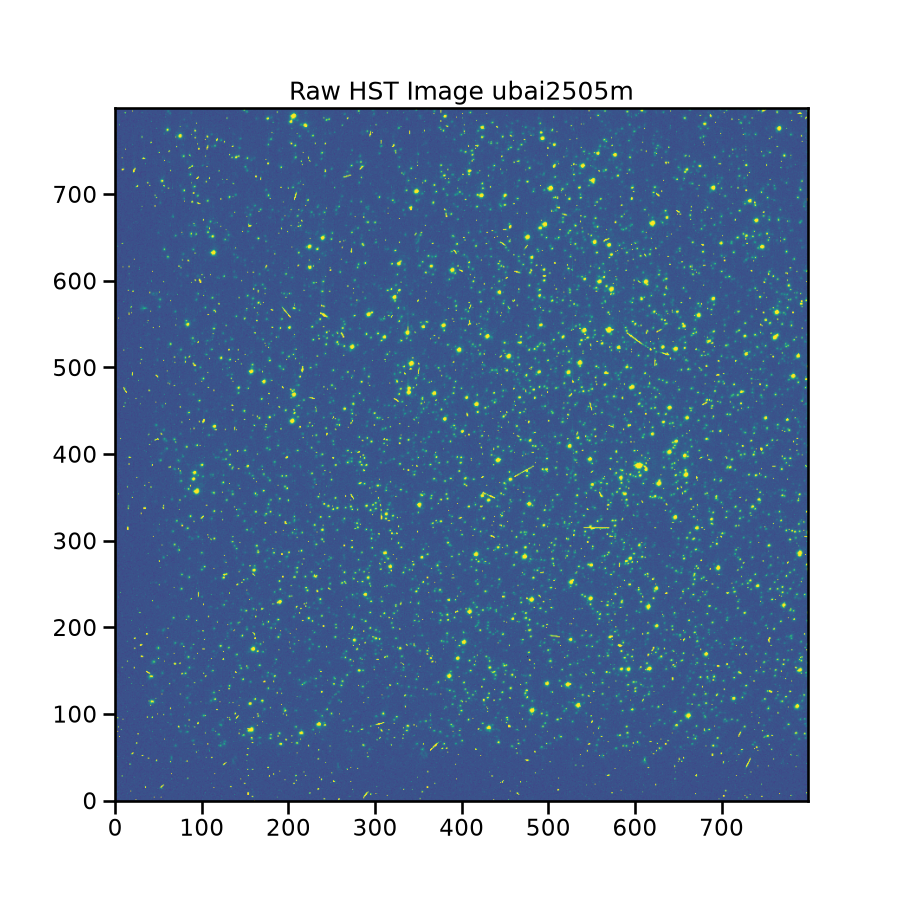

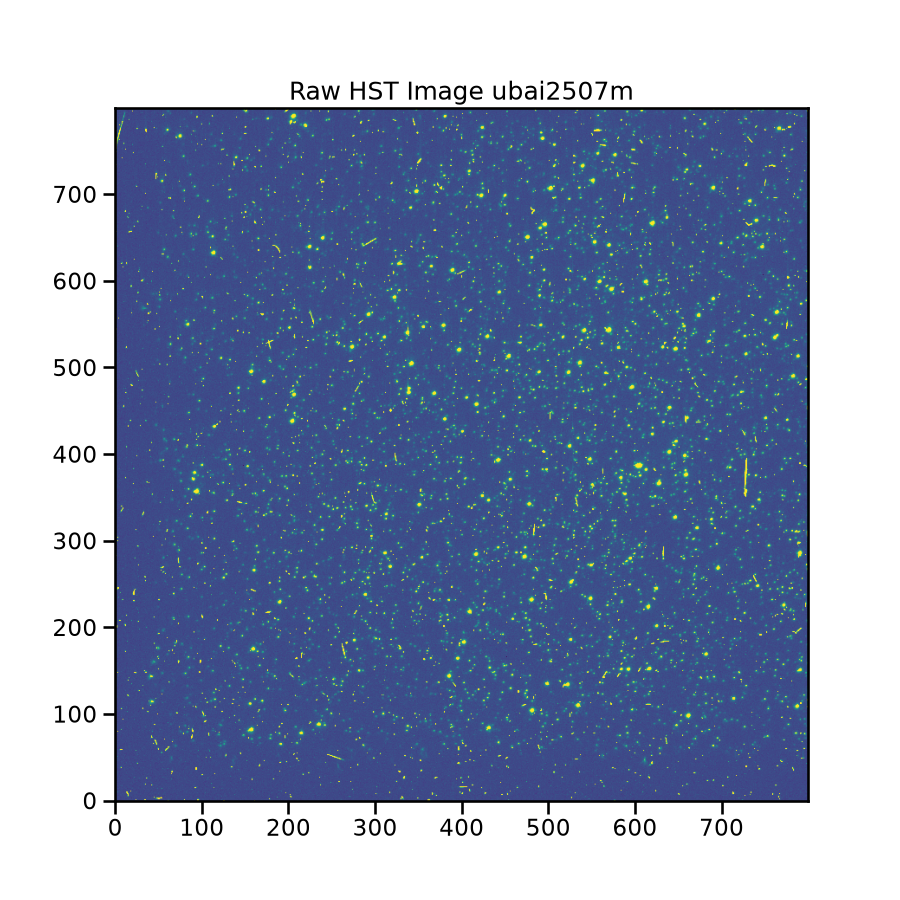

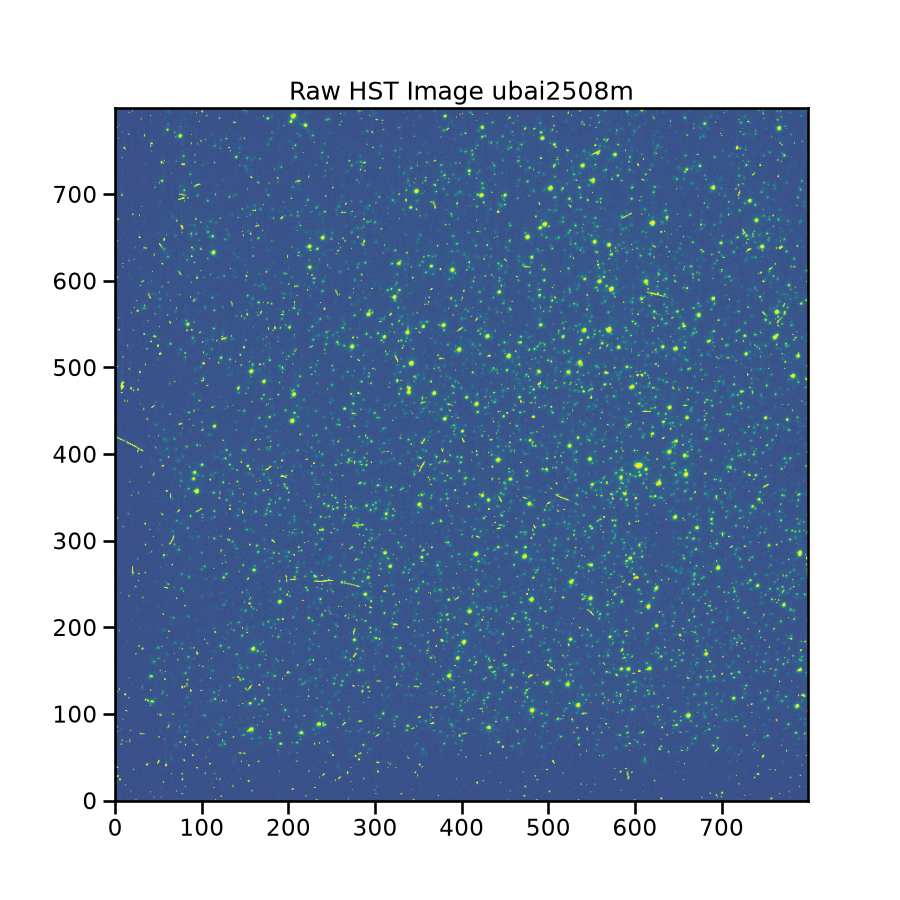

In [7]:
plt.close('all')

# Plot for ubai2505m file
pc_data_u2505= data_u2505[0].copy()
pmin = 0
pmax = 99
vmin, vmax = np.percentile(pc_data_u2505, [pmin, pmax])
fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(pc_data_u2505, origin='lower', vmin=vmin, vmax=vmax)
ax.set_title("Raw HST Image ubai2505m")

# Plot for ubai2507m file
pc_data_u2507= data_u2507[0].copy()
vmin, vmax = np.percentile(pc_data_u2507, [pmin, pmax])
fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(pc_data_u2507, origin='lower', vmin=vmin, vmax=vmax)
ax.set_title("Raw HST Image ubai2507m")

# Plot for ubai2508m file
pc_data_u2508= data_u2508[0].copy()
vmin, vmax = np.percentile(pc_data_u2508, [pmin, pmax])
fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(pc_data_u2508, origin='lower', vmin=vmin, vmax=vmax)
ax.set_title("Raw HST Image ubai2508m")

### Maskfile 

In [8]:
# maskfile_u2505 = 'calibration/ubai2505m/ubai2505m_maskfile.fits'
# maskfile_u2507 = 'calibration/ubai2507m/ubai2507m_maskfile.fits'
# maskfile_u2508 = 'calibration/ubai2508m/ubai2508m_maskfile.fits'
# we need fits to get the data
maskfile_u2505 = fits.getdata('calibration/ubai2505m/ubai2505m_maskfile.fits')
maskfile_u2507 = fits.getdata('calibration/ubai2507m/ubai2507m_maskfile.fits')
maskfile_u2508 = fits.getdata('calibration/ubai2508m/ubai2508m_maskfile.fits')

In [9]:
# View the data of mask files  
mask_data = {
    "u2505_mask": maskfile_u2505,
    "u2507_mask": maskfile_u2507,
    "u2508_mask": maskfile_u2508
}

for name, mask in mask_data.items():
    print(f"\n{name}")
    print("Shape:", mask.shape)
    print("Data type:", mask.dtype)


u2505_mask
Shape: (4, 800, 800)
Data type: >i2

u2507_mask
Shape: (4, 800, 800)
Data type: >i2

u2508_mask
Shape: (4, 800, 800)
Data type: >i2


Text(0.5, 1.0, 'Maskfile ubai2505m')

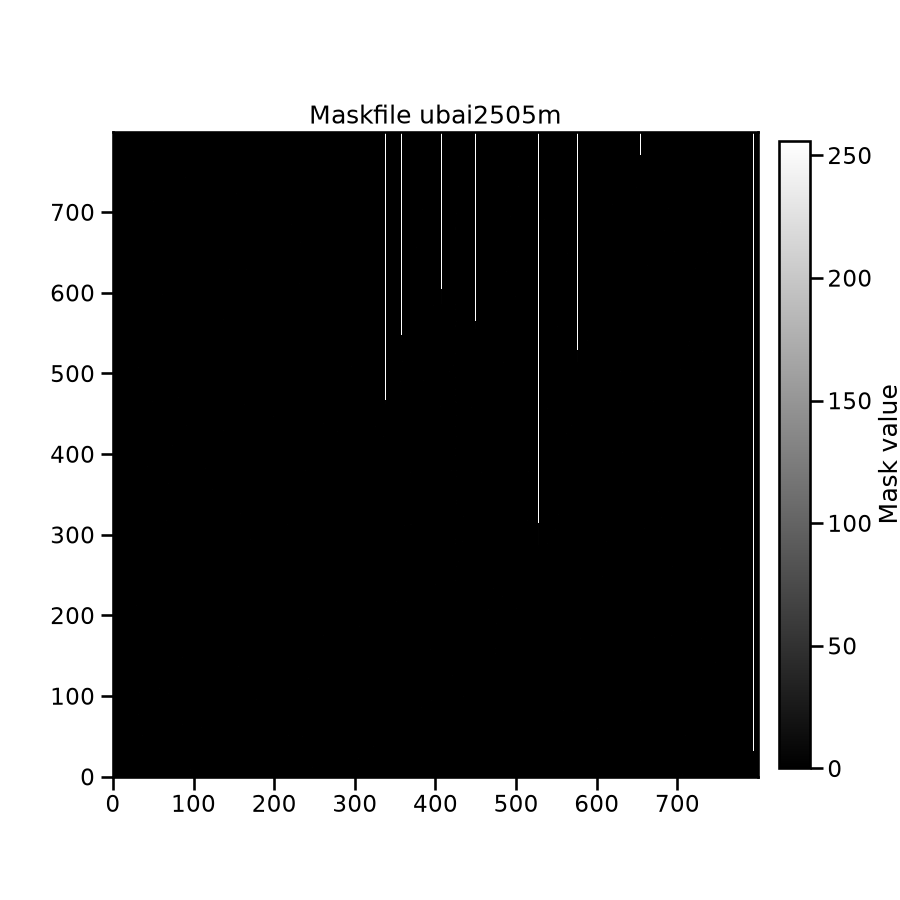

In [57]:
# Plot for ubai2505m file
# https://www.geeksforgeeks.org/python/matplotlib-pyplot-imshow-in-python/

plt.close('all')
maskplot_u2505= maskfile_u2505[0].copy()
maskplot_u2507= maskfile_u2507[0].copy()
maskplot_u2508= maskfile_u2508[0].copy()
fig, ax = plt.subplots(figsize=(9, 9))

plt.imshow(maskplot_u2505, origin="lower", cmap="gray", interpolation='nearest')
plt.colorbar(label="Mask value", shrink=0.95, fraction=0.045, pad=0.03)
ax.set_title("Maskfile ubai2505m")

In [60]:
from matplotlib.colors import ListedColormap

Text(0.5, 1.0, 'Masked Values plot HST Image ubai2505m')

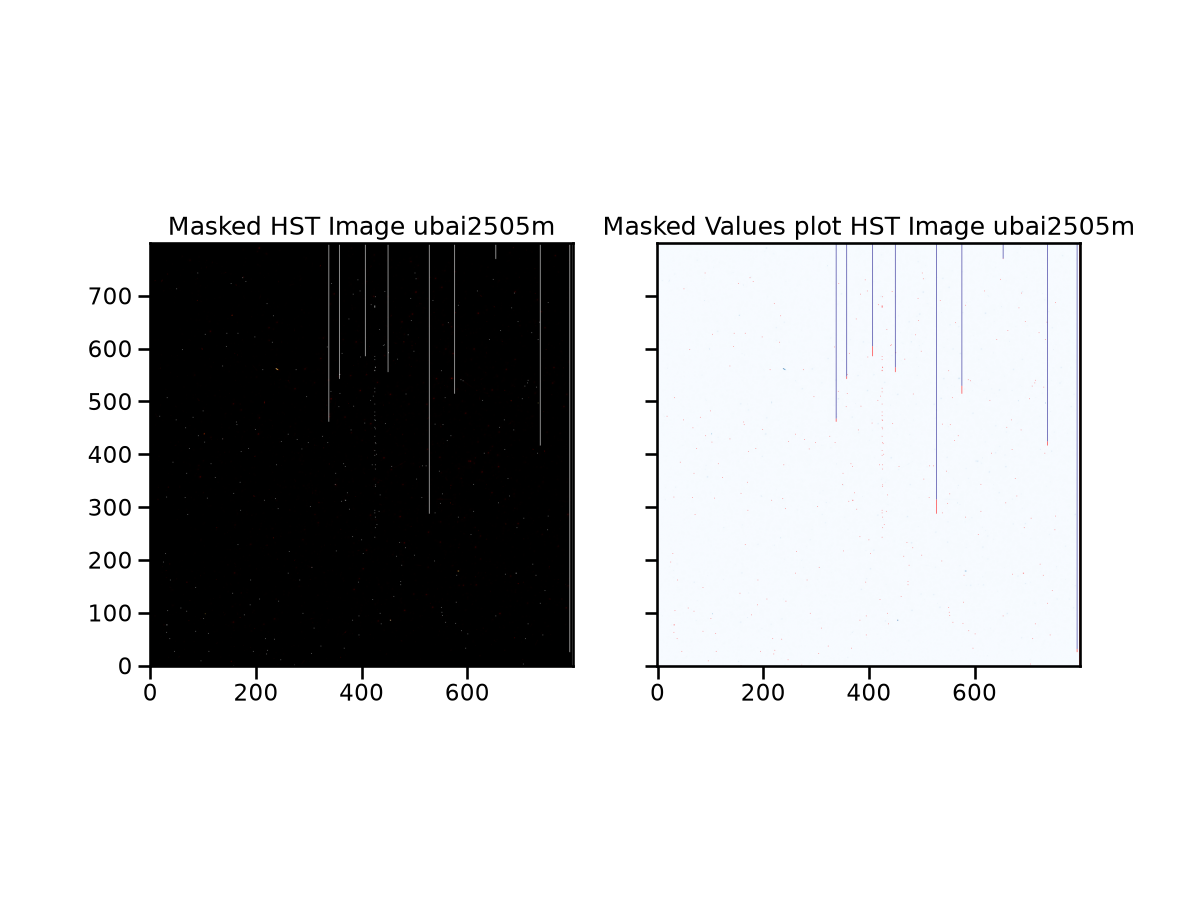

In [81]:
flag1 = maskplot_u2505 == 0
flag2 = maskplot_u2505 == 2
flag3 = maskplot_u2505 == 256

combined_flag = flag2 | flag3
masked_image_u2505 = np.ma.masked_where(combined_flag, pc_data_u2505)

plt.close('all')
vmin = masked_image_u2505.min()
vmax = masked_image_u2505.max()
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 9), sharex=True, sharey=True)
ax1.imshow(masked_image_u2505, origin='lower',cmap="afmhot", vmin=vmin, vmax=vmax)
ax1.set_title("Masked HST Image ubai2505m")

ax2.imshow(pc_data_u2505, origin='lower', cmap='Blues')
ax2.imshow(np.ma.masked_where(maskplot_u2505 != 2, maskplot_u2505 == 2), origin='lower', cmap='autumn')
ax2.imshow(np.ma.masked_where(maskplot_u2505 != 256, maskplot_u2505 == 256), origin='lower', cmap='plasma')
ax2.set_title("Masked Values plot HST Image ubai2505m")
